# SeqInsight: sequence modelling coursework
RNN / LSTM implementations, SST-2 sentiment classification, attribution, and small-corpus generation.
Based on NUS CEG5304 course scaffolding. Historical outputs are retained; see README.md for evidence boundaries.
Run this notebook from this repository root. Install the pinned environment first.

## Runtime and model implementations

In [2]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
block_type = None


In [3]:

class myRNNBlock(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_layers: int = 1, batch_first: bool = False, dropout: float = 0.):
        super(myRNNBlock, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.batch_first = batch_first
        self.dropout = dropout

        ##############################################################################
        # TODO: Initialize weights and biases for each layer                         #
        ##############################################################################
        self.weight_ih = nn.ParameterList()  # Input-to-hidden weights
        self.weight_hh = nn.ParameterList()  # Hidden-to-hidden weights
        self.bias_ih = nn.ParameterList()    # Input-to-hidden biases
        self.bias_hh = nn.ParameterList()    # Hidden-to-hidden biases
        
        for layer in range(num_layers):
            # For the first layer, input size is the actual input dimension
            # For subsequent layers, input size is the hidden size of previous layer
            layer_input_size = input_size if layer == 0 else hidden_size
            
            # Weight matrix from input to hidden state (W_ih)
            self.weight_ih.append(nn.Parameter(torch.randn(hidden_size, layer_input_size)))
            
            # Weight matrix from hidden to hidden state (W_hh) 
            self.weight_hh.append(nn.Parameter(torch.randn(hidden_size, hidden_size)))
            
            # Bias for input-to-hidden transformation (b_ih)
            self.bias_ih.append(nn.Parameter(torch.randn(hidden_size)))
            
            # Bias for hidden-to-hidden transformation (b_hh)
            self.bias_hh.append(nn.Parameter(torch.randn(hidden_size)))

        ##############################################################################
        #                             END OF YOUR CODE                               #
        ##############################################################################

        self.dropout_layer = nn.Dropout(p=dropout) if dropout > 0 else None
        self.reset_parameters()

    def reset_parameters(self):
        ##############################################################################
        # TODO: Reset the parameters of the layers                                   #
        ##############################################################################
        # Initialize parameters using Xavier uniform initialization for weights
        # and zero initialization for biases
        for layer in range(self.num_layers):
            # Xavier uniform initialization for input-to-hidden weights
            nn.init.xavier_uniform_(self.weight_ih[layer])
            
            # Xavier uniform initialization for hidden-to-hidden weights  
            nn.init.xavier_uniform_(self.weight_hh[layer])
            
            # Initialize biases to zero
            nn.init.zeros_(self.bias_ih[layer])
            nn.init.zeros_(self.bias_hh[layer])

        ##############################################################################
        #                             END OF YOUR CODE                               #
        ##############################################################################

    def forward(self, x, hidden):
        if self.batch_first:
            batch_size, seq_len, _ = x.size()
        else:
            seq_len, batch_size, _ = x.size()

        outputs = []
        hidden_next = []

        for layer in range(self.num_layers):
            ##############################################################################
            # TODO: Implement the forward pass for each layer                            #
            ##############################################################################
            layer_input = x
            layer_hidden = hidden[layer] if layer < len(hidden) else torch.zeros(batch_size, self.hidden_size, device=x.device)
            
            layer_outputs = []
            h = layer_hidden
            
            for t in range(seq_len):
                # Get input at time step t
                if self.batch_first:
                    x_t = layer_input[:, t, :]  # [batch_size, input_size]
                else:
                    x_t = layer_input[t, :, :]  # [batch_size, input_size]
                
                # Input-to-hidden transformation: x_t @ W_ih + b_ih
                ih = torch.mm(x_t, self.weight_ih[layer].t()) + self.bias_ih[layer]
                
                # Hidden-to-hidden transformation: h @ W_hh + b_hh
                hh = torch.mm(h, self.weight_hh[layer].t()) + self.bias_hh[layer]
                
                # Compute new hidden state with tanh activation
                h = torch.tanh(ih + hh)
                
                # Apply dropout if specified
                if self.dropout_layer is not None and self.training:
                    h = self.dropout_layer(h)
                
                layer_outputs.append(h)
            
            # Stack outputs for this layer
            if self.batch_first:
                x = torch.stack(layer_outputs, dim=1)  # [batch_size, seq_len, hidden_size]
            else:
                x = torch.stack(layer_outputs, dim=0)  # [seq_len, batch_size, hidden_size]
            
            # Store final hidden state for this layer
            hidden_next.append(h)

            ##############################################################################
            #                             END OF YOUR CODE                               #
            ##############################################################################
        return x, hidden_next


In [4]:
class myLSTMBlock(nn.Module):
    ##############################################################################
    # TODO: Implement LSTM block                                                 #
    # Also, you may refer to the previous RNN block for reference                #
    # However, built-in functions like nn.RNN / nn.LSTM are not allowed          #
    ##############################################################################
    def __init__(self, input_size: int, hidden_size: int, num_layers: int = 1, batch_first: bool = False, dropout: float = 0.):
        super(myLSTMBlock, self).__init__()
        
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.batch_first = batch_first
        self.dropout = dropout
        
        # Initialize weight and bias parameters for each layer
        # For LSTM, we need weights for input gate, forget gate, output gate, and cell gate
        # Each gate has input-to-hidden and hidden-to-hidden weights
        
        self.weight_ih = nn.ParameterList()  # Input-to-hidden weights for all gates
        self.weight_hh = nn.ParameterList()  # Hidden-to-hidden weights for all gates
        self.bias_ih = nn.ParameterList()    # Input-to-hidden biases for all gates
        self.bias_hh = nn.ParameterList()    # Hidden-to-hidden biases for all gates
        
        for layer in range(num_layers):
            # For the first layer, input size is the actual input dimension
            # For subsequent layers, input size is the hidden size of previous layer
            layer_input_size = input_size if layer == 0 else hidden_size
            
            # Each layer has 4 gates: input, forget, output, cell
            # Weight matrix from input to hidden state for all 4 gates (W_ih)
            self.weight_ih.append(nn.Parameter(torch.randn(4 * hidden_size, layer_input_size)))
            
            # Weight matrix from hidden to hidden state for all 4 gates (W_hh)
            self.weight_hh.append(nn.Parameter(torch.randn(4 * hidden_size, hidden_size)))
            
            # Bias for input-to-hidden transformation for all 4 gates (b_ih)
            self.bias_ih.append(nn.Parameter(torch.randn(4 * hidden_size)))
            
            # Bias for hidden-to-hidden transformation for all 4 gates (b_hh)
            self.bias_hh.append(nn.Parameter(torch.randn(4 * hidden_size)))

        self.dropout_layer = nn.Dropout(p=dropout) if dropout > 0 else None
        self.reset_parameters()

    def reset_parameters(self):
        # Initialize parameters using Xavier uniform initialization for weights
        # and zero initialization for biases
        for layer in range(self.num_layers):
            # Xavier uniform initialization for input-to-hidden weights
            nn.init.xavier_uniform_(self.weight_ih[layer])
            
            # Xavier uniform initialization for hidden-to-hidden weights  
            nn.init.xavier_uniform_(self.weight_hh[layer])
            
            # Initialize biases to zero
            nn.init.zeros_(self.bias_ih[layer])
            nn.init.zeros_(self.bias_hh[layer])

    def forward(self, x, hidden):
        if self.batch_first:
            batch_size, seq_len, _ = x.size()
        else:
            seq_len, batch_size, _ = x.size()

        # Extract hidden state and cell state
        if hidden is None:
            h_0 = torch.zeros(self.num_layers, batch_size, self.hidden_size, device=x.device)
            c_0 = torch.zeros(self.num_layers, batch_size, self.hidden_size, device=x.device)
        else:
            h_0, c_0 = hidden

        outputs = []
        hidden_next = []
        cell_next = []

        for layer in range(self.num_layers):
            # Get hidden state and cell state for current layer
            h_t = h_0[layer]  # Current hidden state for this layer
            c_t = c_0[layer]  # Current cell state for this layer
            
            # Initialize list to store outputs for this layer across time steps
            layer_outputs = []
            
            # Process each time step
            for t in range(seq_len):
                if self.batch_first:
                    x_t = x[:, t, :]  # Shape: (batch_size, input_size)
                else:
                    x_t = x[t, :, :]  # Shape: (batch_size, input_size)
                
                # Compute input-to-hidden transformation for all gates
                gi = torch.matmul(x_t, self.weight_ih[layer].t()) + self.bias_ih[layer]
                
                # Compute hidden-to-hidden transformation for all gates
                gh = torch.matmul(h_t, self.weight_hh[layer].t()) + self.bias_hh[layer]
                
                # Split the transformations for each gate
                i_i, i_f, i_o, i_g = gi.chunk(4, 1)  # input, forget, output, cell gates from input
                h_i, h_f, h_o, h_g = gh.chunk(4, 1)  # input, forget, output, cell gates from hidden
                
                # Apply sigmoid activation to gates
                input_gate = torch.sigmoid(i_i + h_i)     # Input gate
                forget_gate = torch.sigmoid(i_f + h_f)    # Forget gate  
                output_gate = torch.sigmoid(i_o + h_o)    # Output gate
                cell_gate = torch.tanh(i_g + h_g)         # Cell gate (candidate values)
                
                # Update cell state
                c_t = forget_gate * c_t + input_gate * cell_gate
                
                # Update hidden state
                h_t = output_gate * torch.tanh(c_t)
                
                # Apply dropout if specified
                if self.dropout_layer is not None and self.training:
                    h_t = self.dropout_layer(h_t)
                
                # Store output for this time step
                if self.batch_first:
                    layer_outputs.append(h_t.unsqueeze(1))  # Add time dimension
                else:
                    layer_outputs.append(h_t.unsqueeze(0))  # Add time dimension
            
            # Concatenate outputs across time dimension
            if self.batch_first:
                x = torch.cat(layer_outputs, dim=1)  # Shape: (batch_size, seq_len, hidden_size)
            else:
                x = torch.cat(layer_outputs, dim=0)  # Shape: (seq_len, batch_size, hidden_size)
            
            # Store final hidden and cell states for this layer
            hidden_next.append(h_t)
            cell_next.append(c_t)

        return x, (torch.stack(hidden_next), torch.stack(cell_next))
    ##############################################################################
    #                             END OF YOUR CODE                               #
    ##############################################################################

## SST-2 data preparation

In [5]:
from torchtext.datasets import SST2
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator
from torch.utils.data import DataLoader
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import json

In [6]:
batch_size=16

train_datapipe = SST2(split="train")
dev_datapipe = SST2(split="dev")

# Tokenize and build vocabulary
tokenizer = get_tokenizer("basic_english")
vocab = build_vocab_from_iterator((tokenizer(text) for text, _ in train_datapipe), specials=["<PAD>", "<UNK>"])

##############################################################################
# TODO: You can add more special tokens to the vocabulary                    #
# For example, you can add "<BOS>", "<EOS>" tokens to the vocabulary         #
##############################################################################
# Add special tokens for beginning and end of sequence
vocab.append_token("<BOS>")
vocab.append_token("<EOS>")

# Define text transformation function to tokenize and convert to tensor
# Use a local tokenizer to avoid being overwritten by later cells (e.g., Task 4)
_local_tok = get_tokenizer("basic_english")

def text_transform(text):
    tokens = _local_tok(text)
    tokens = ["<BOS>"] + tokens + ["<EOS>"]
    return torch.tensor([vocab[token] for token in tokens], dtype=torch.long)
##############################################################################
#                             END OF YOUR CODE                               #
##############################################################################

# Update default padding index (optional)
vocab.set_default_index(vocab["<UNK>"])

def apply_transform(x):
    original_text = x[0]  # Original sentence
    tokenized = text_transform(original_text)  # Tokenize and transform to token_ids
    target = x[1]  # target
    return {"original_text": original_text, "token_ids": tokenized, "target": target}

print(f"SST2 transformed data saved.")

# transform the dataset
train_datapipe = SST2(split="train").map(apply_transform)
transformed_train = list(train_datapipe)
transformed_train_serializable = [
    {
        "original_text": item["original_text"],  # Add the original sentence
        "token_ids": item["token_ids"].tolist(),  # Convert token_ids tensor to list
        "target": item["target"]  # Keep the label
    }
    for item in transformed_train
]
import json
import os

# Save the transformed dataset into a JSON file
os.makedirs("tokenizer", exist_ok=True)
with open("tokenizer/sst2_sentence_piece.json", "w") as f:
    json.dump(transformed_train_serializable, f, indent=4)

print(f"Transformed data saved to tokenizer/sst2_sentence_piece.json")


SST2 transformed data saved.
Transformed data saved to tokenizer/sst2_sentence_piece.json


In [7]:
train_datapipe = train_datapipe.batch(batch_size).rows2columnar(["token_ids", "target"])
dev_datapipe = SST2(split="dev").map(apply_transform).batch(batch_size).rows2columnar(["token_ids", "target"])

train_dataloader = DataLoader(train_datapipe, batch_size=None)
dev_dataloader = DataLoader(dev_datapipe, batch_size=None)

## Sentiment classifier

In [8]:

class Classifier(nn.Module):
    def __init__(self, vocab_size, embed_size, hidden_size, num_layers, num_classes, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=0)
        if block_type == "rnn":
            self.model = myRNNBlock(embed_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
            self.num_hidden = 1
        elif block_type == "lstm":
            self.model = myLSTMBlock(embed_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
            self.num_hidden = 2

        self.fc = nn.Linear(hidden_size * self.num_hidden, num_classes)
        
    def forward(self, x):
        ##############################################################################
        # TODO: Implement the forward pass for the binary text classifier            #
        ##############################################################################
        # Convert input tokens to embeddings
        embedded = self.embedding(x)  # Shape: (batch_size, seq_len, embed_size)
        
        # Initialize hidden state for RNN/LSTM
        batch_size = x.size(0)
        if block_type == "rnn":
            # For RNN, initialize hidden state as list of tensors for each layer
            hidden = [torch.zeros(batch_size, self.model.hidden_size, device=x.device) 
                     for _ in range(self.model.num_layers)]
        elif block_type == "lstm":
            # For LSTM, initialize both hidden state and cell state
            h_0 = torch.zeros(self.model.num_layers, batch_size, self.model.hidden_size, device=x.device)
            c_0 = torch.zeros(self.model.num_layers, batch_size, self.model.hidden_size, device=x.device)
            hidden = (h_0, c_0)
        
        # Pass through RNN/LSTM model
        output, final_hidden = self.model(embedded, hidden)
        
        # Extract final hidden states for classification
        # Masked mean pooling over valid tokens to avoid PAD contamination (PAD=0)
        mask = (x != 0).float().unsqueeze(-1)  # (batch_size, seq_len, 1)
        masked_sum = (output * mask).sum(dim=1)  # (batch_size, hidden_size)
        lengths = mask.sum(dim=1).clamp(min=1.0)  # (batch_size, 1)
        pooled = masked_sum / lengths  # (batch_size, hidden_size)

        if block_type == "rnn":
            # RNN: pooled is (batch_size, hidden_size) => matches fc(in=hidden_size)
            final_states = pooled
        elif block_type == "lstm":
            # LSTM: fc expects 2*hidden_size; duplicate pooled to match
            final_states = torch.cat([pooled, pooled], dim=1)  # (batch_size, 2 * hidden_size)
        
        # Apply final classification layer
        logits = self.fc(final_states)  # Shape: (batch_size, num_classes)
        
        return logits
        ##############################################################################
        #                             END OF YOUR CODE                               #
        ##############################################################################


## Training and validation

In [9]:
import torch.optim as optim

def train_model(batch_size=16, embed_size=128, hidden_size=256, num_layers=2, num_epochs=5, lr=0.001):

    model = Classifier(len(vocab), embed_size, hidden_size, num_layers, num_classes=2, dropout=0.2).to(device)
    print(model)
    model.train()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0
        correct = 0
        total = 0

        for batch in tqdm(train_dataloader):

            inputs = torch.nn.utils.rnn.pad_sequence(batch["token_ids"], batch_first=True).to(device)
            labels = torch.tensor(batch["target"], dtype=torch.long).to(device)
            ##############################################################################
            # TODO: Implement the training loop for the binary text classifier           #
            ##############################################################################
            # Zero gradients from previous iteration
            optimizer.zero_grad()
            
            # Forward pass: compute predictions
            outputs = model(inputs)  # Shape: (batch_size, num_classes)
            
            # Compute loss
            loss = criterion(outputs, labels)
            
            # Backward pass: compute gradients
            loss.backward()
            
            # Update parameters
            optimizer.step()
            
            # Update statistics
            epoch_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            ##############################################################################
            #                             END OF YOUR CODE                               #
            ##############################################################################

        accuracy = 100 * correct / total
        print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_loss:.4f}, Accuracy: {accuracy:.2f}%")
        
    if not os.path.exists("models"):
        os.makedirs("models")
    torch.save(model.state_dict(), f"models/{block_type}_classifier.pth")

    return model, vocab

In [10]:
def evaluate_model(model, dev_dataloader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in dev_dataloader:
            inputs = torch.nn.utils.rnn.pad_sequence(batch["token_ids"], batch_first=True).to(device)
            labels = torch.tensor(batch["target"], dtype=torch.long).to(device)

            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Validation Accuracy: {100 * correct / total:.2f}%")

## Historical RNN classification run

In [11]:
# TODO: Set the block_type to either 'rnn' or 'lstm' to train the corresponding model #
block_type = 'rnn'

# END OF YOUR CODE #

model, vocab = train_model()
evaluate_model(model, dev_dataloader)

Classifier(
  (embedding): Embedding(14764, 128, padding_idx=0)
  (model): myRNNBlock(
    (weight_ih): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256x128 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
    )
    (weight_hh): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
    )
    (bias_ih): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256 (cuda:0)]
    )
    (bias_hh): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256 (cuda:0)]
    )
    (dropout_layer): Dropout(p=0.2, inplace=False)
  )
  (fc): Linear(in_features=256, out_features=2, bias=True)
)


4210it [02:55, 24.02it/s]


Epoch [1/5], Loss: 1946.0263, Accuracy: 77.23%


4210it [02:52, 24.34it/s]


Epoch [2/5], Loss: 1107.3783, Accuracy: 89.28%


...

Epoch [3/5], Loss: 883.5376, Accuracy: 91.82%


4210it [02:53, 24.31it/s]


Epoch [4/5], Loss: 768.2562, Accuracy: 93.01%


4210it [02:53, 24.31it/s]


Epoch [5/5], Loss: 696.0042, Accuracy: 93.71%
Validation Accuracy: 78.21%


## Classification learning curves

Training RNN model...
Classifier(
  (embedding): Embedding(14764, 128, padding_idx=0)
  (model): myRNNBlock(
    (weight_ih): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256x128 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
    )
    (weight_hh): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
    )
    (bias_ih): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256 (cuda:0)]
    )
    (bias_hh): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256 (cuda:0)]
    )
    (dropout_layer): Dropout(p=0.2, inplace=False)
  )
  (fc): Linear(in_features=256, out_features=2, bias=True)
)


Training Epoch 1: 4210it [02:53, 24.30it/s]


Epoch [1/5]
  Train Loss: 0.4596, Train Acc: 77.27%
  Val Loss: 0.4732, Val Acc: 79.36%
--------------------------------------------------


Training Epoch 2: 4210it [02:53, 24.23it/s]


Epoch [2/5]
  Train Loss: 0.2644, Train Acc: 89.22%
  Val Loss: 0.4891, Val Acc: 80.62%
--------------------------------------------------


...

Epoch [3/5]
  Train Loss: 0.2106, Train Acc: 91.74%
  Val Loss: 0.4523, Val Acc: 81.88%
--------------------------------------------------


Training Epoch 4: 4210it [02:52, 24.34it/s]


Epoch [4/5]
  Train Loss: 0.1834, Train Acc: 92.86%
  Val Loss: 0.4736, Val Acc: 81.77%
--------------------------------------------------


Training Epoch 5: 4210it [02:53, 24.29it/s]


Epoch [5/5]
  Train Loss: 0.1679, Train Acc: 93.56%
  Val Loss: 0.4871, Val Acc: 81.77%
--------------------------------------------------


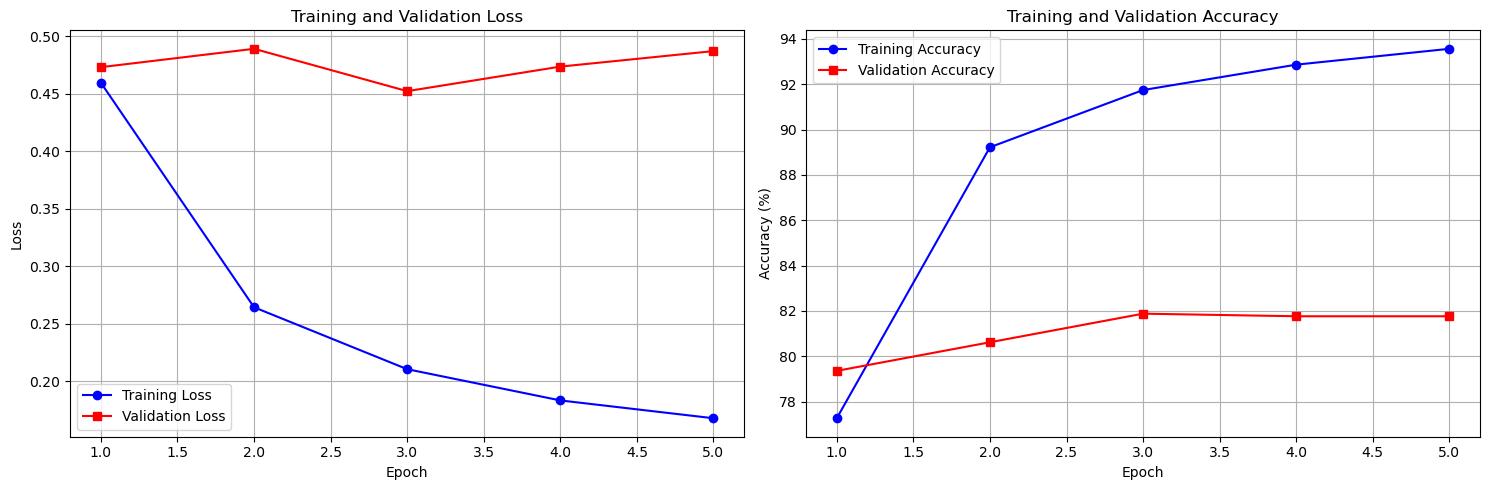

Saved training curves to figures\task2_curves_rnn.png


In [12]:
##############################################################################
# TODO: Visualize the training and validation curves                         #
##############################################################################
import torch.optim as optim
import matplotlib.pyplot as plt

def train_model_with_validation(batch_size=16, embed_size=128, hidden_size=256, num_layers=2, num_epochs=5, lr=0.001):
    """
    Modified training function that tracks both training and validation metrics
    """
    model = Classifier(len(vocab), embed_size, hidden_size, num_layers, num_classes=2, dropout=0.2).to(device)
    print(model)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    # Lists to store metrics for plotting
    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        epoch_loss = 0
        correct = 0
        total = 0
        train_batch_count = 0
        
        for batch in tqdm(train_dataloader, desc=f'Training Epoch {epoch+1}'):
            inputs = torch.nn.utils.rnn.pad_sequence(batch["token_ids"], batch_first=True).to(device)
            labels = torch.tensor(batch["target"], dtype=torch.long).to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            train_batch_count += 1
        
        train_accuracy = 100 * correct / total
        train_loss = epoch_loss / max(1, train_batch_count)
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        
        # Validation phase
        model.eval()
        val_loss = 0
        val_correct = 0
        val_total = 0
        val_batch_count = 0
        
        with torch.no_grad():
            for batch in dev_dataloader:
                inputs = torch.nn.utils.rnn.pad_sequence(batch["token_ids"], batch_first=True).to(device)
                labels = torch.tensor(batch["target"], dtype=torch.long).to(device)
                
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                val_batch_count += 1
        
        val_accuracy = 100 * val_correct / val_total
        val_loss = val_loss / max(1, val_batch_count)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)
        
        print(f"Epoch [{epoch + 1}/{num_epochs}]")
        print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%")
        print(f"  Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")
        print("-" * 50)
    
    # Plot training curves
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    # Loss curves
    epochs = range(1, num_epochs + 1)
    ax1.plot(epochs, train_losses, 'b-', label='Training Loss', marker='o')
    ax1.plot(epochs, val_losses, 'r-', label='Validation Loss', marker='s')
    ax1.set_title('Training and Validation Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)
    
    # Accuracy curves
    ax2.plot(epochs, train_accuracies, 'b-', label='Training Accuracy', marker='o')
    ax2.plot(epochs, val_accuracies, 'r-', label='Validation Accuracy', marker='s')
    ax2.set_title('Training and Validation Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    
    # Save figure and also display
    os.makedirs("figures", exist_ok=True)
    fig_path = os.path.join("figures", f"task2_curves_{block_type}.png")
    plt.savefig(fig_path, dpi=200)
    plt.show()
    print(f"Saved training curves to {fig_path}")
    
    # Save model
    if not os.path.exists("models"):
        os.makedirs("models")
    torch.save(model.state_dict(), f"models/{block_type}_classifier.pth")
    
    return model, vocab

# Train the model with visualization
if 'block_type' in globals() and block_type:
    print(f"Training {block_type.upper()} model...")
    model, vocab = train_model_with_validation()
else:
    print("Please set block_type to 'rnn' or 'lstm' first")
##############################################################################
#                             END OF YOUR CODE                               #
##############################################################################


## Embedding visualisation

In [13]:
import random
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

def visualize_embeddings(embedding_weights, tokenizer, method="pca", num_samples=200, figsize=(6, 6)):

    ##############################################################################
    # TODO: Implement the sampling of tokens and their corresponding embeddings  #
    ##############################################################################
    # Get vocabulary tokens and their indices
    vocab_tokens = list(vocab.get_stoi().keys())
    vocab_size = len(vocab_tokens)
    
    # Sample tokens to visualize
    if num_samples > vocab_size:
        num_samples = vocab_size
        
    # Sample random indices
    sampled_indices = random.sample(range(vocab_size), num_samples)
    
    # Get the corresponding tokens and embeddings
    sampled_tokens = [vocab_tokens[i] for i in sampled_indices]
    sampled_embedding_weights = embedding_weights[sampled_indices]
    
    print(f"Visualizing {len(sampled_tokens)} token embeddings")
    print(f"Sample tokens: {sampled_tokens[:10]}...")  # Show first 10 tokens
    ##############################################################################
    #                             END OF YOUR CODE                               #
    ##############################################################################

    # Dimensionality reduction
    if method.lower() == "pca":
        reducer = PCA(n_components=2)
    elif method.lower() == "tsne":
        reducer = TSNE(n_components=2, random_state=42, perplexity=30)
    else:
        raise ValueError("Unsupported method. Use 'pca' or 'tsne'.")

    reduced_embeddings = reducer.fit_transform(sampled_embedding_weights)

    # Plot the embeddings
    x_coords = reduced_embeddings[:, 0]
    y_coords = reduced_embeddings[:, 1]

    plt.figure(figsize=figsize)
    for i, token in enumerate(sampled_tokens):
        plt.scatter(x_coords[i], y_coords[i], color="blue", s=10)
        plt.text(x_coords[i] + 0.01, y_coords[i] + 0.01, token, fontsize=8)

    plt.title(f"Word Embeddings Visualization ({method.upper()})")
    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")
    plt.show()

Visualizing 40 token embeddings
Sample tokens: ['festival', 'recessive', 'laissez-passer', 'rapid', 'withholds', 'buscemi', 'thirst', 'honoring', 'normal', 'retrospectively']...


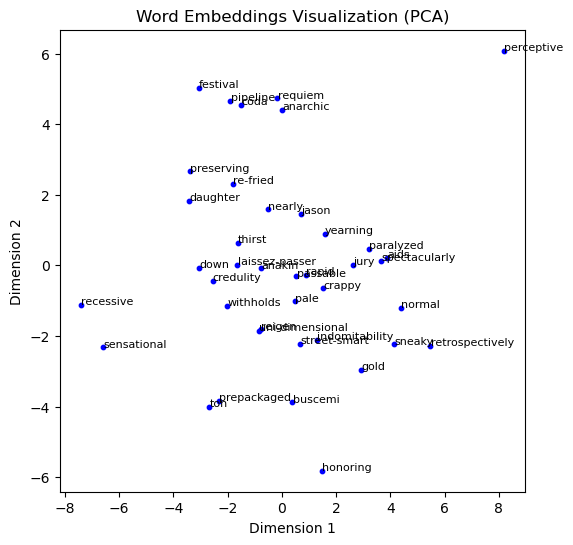

In [14]:

embedding_weights = model.embedding.weight.detach().cpu().numpy()

# Visualize with PCA/t-SNE
vis_method = "pca"
visualize_embeddings(embedding_weights, tokenizer, method=vis_method, num_samples=40)

## Gradient saliency

Analyzing model interpretability...

Text: This movie was absolutely fantastic and amazing!
Prediction: Positive (Confidence: 1.000)
Token importances:
  this: 1.000
  movie: 0.313
  was: 0.232
  absolutely: 0.137
  fantastic: 0.041
  and: 0.086
  amazing: 0.021
  !: 0.025

Text: I hate this boring and terrible film.
Prediction: Negative (Confidence: 1.000)
Token importances:
  i: 0.992
  hate: 1.000
  this: 0.585
  boring: 0.776
  and: 0.859
  terrible: 0.888
  film: 0.971
  .: 0.582

Text: The plot was okay but the acting was great.
Prediction: Positive (Confidence: 0.922)
Token importances:
  the: 1.000
  plot: 0.769
  was: 0.436
  okay: 0.531
  but: 0.418
  the: 0.509
  acting: 0.528
  was: 0.447
  great: 0.459
  .: 0.138

Text: Not bad, could have been better though.
Prediction: Negative (Confidence: 1.000)
Token importances:
  not: 0.166
  bad: 0.145
  ,: 0.862
  could: 0.988
  have: 1.000
  been: 0.460
  better: 0.474
  though: 0.554
  .: 0.299


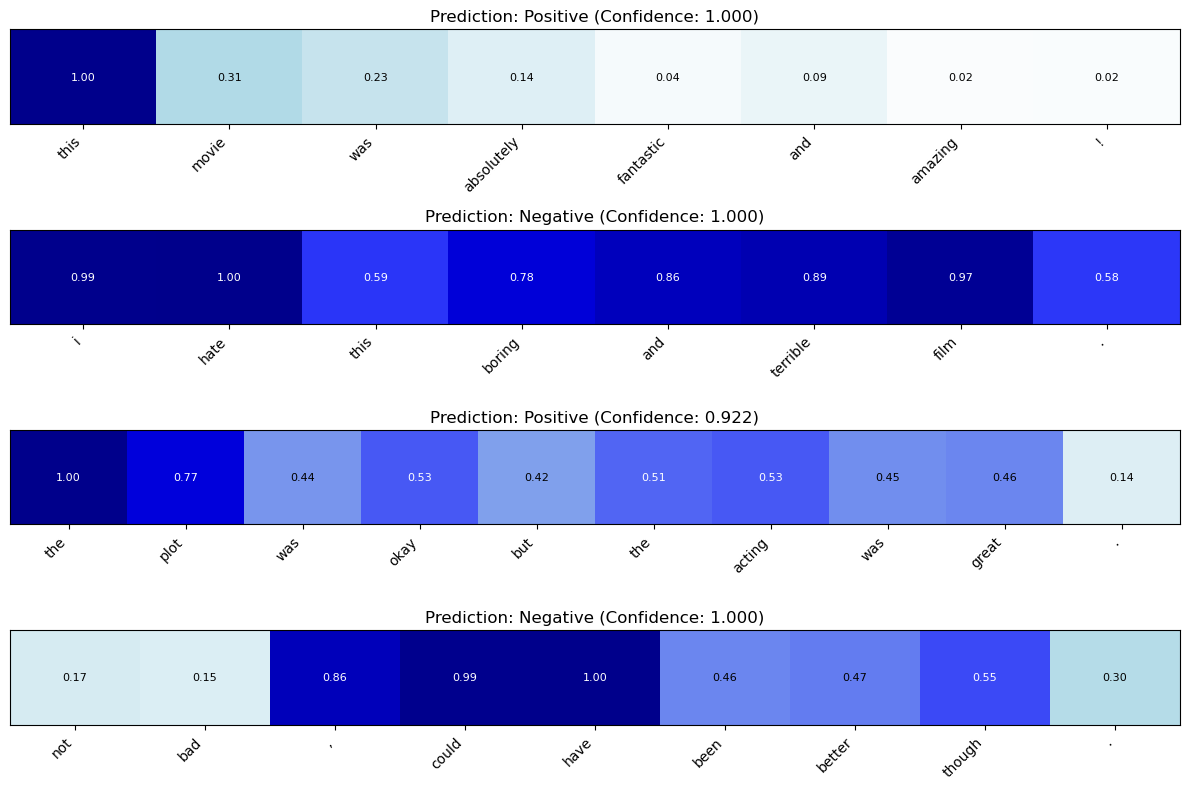

In [15]:
##############################################################################
# TODO: Explore the model's interpretability
##############################################################################
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

def interpret_model_predictions(model, tokenizer, vocab, texts, max_length=50):
    """
    Analyze which words contribute most to model predictions using gradient-based saliency
    """
    model.eval()
    
    results = []
    
    for text in texts:
        # Tokenize and prepare input
        tokens = tokenizer(text)
        if len(tokens) > max_length:
            tokens = tokens[:max_length]
        
        token_ids = torch.tensor([[vocab[token] for token in tokens]], dtype=torch.long).to(device)
        token_ids.requires_grad_(False)
        
        # Create embedding layer that requires gradient
        embeddings = model.embedding(token_ids)
        embeddings.requires_grad_(True)
        embeddings.retain_grad()
        
        # Forward pass through the rest of the model
        batch_size = embeddings.size(0)
        if block_type == "rnn":
            hidden = [torch.zeros(batch_size, model.model.hidden_size, device=device) 
                     for _ in range(model.model.num_layers)]
        elif block_type == "lstm":
            h_0 = torch.zeros(model.model.num_layers, batch_size, model.model.hidden_size, device=device)
            c_0 = torch.zeros(model.model.num_layers, batch_size, model.model.hidden_size, device=device)
            hidden = (h_0, c_0)
        
        # Get model output
        rnn_output, final_hidden = model.model(embeddings, hidden)
        
        # Build final states consistent with Classifier.forward (masked mean pooling)
        pad_idx = 0
        mask = (token_ids != pad_idx).float().unsqueeze(-1)  # (B, L, 1)
        pooled = (rnn_output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)  # (B, hidden)
        if block_type == "rnn":
            final_states = pooled  # (B, hidden)
        elif block_type == "lstm":
            # Classifier.fc for LSTM expects 2*hidden; duplicate pooled to match when needed
            if model.fc.in_features == pooled.size(1) * 2:
                final_states = torch.cat([pooled, pooled], dim=1)
            else:
                final_states = pooled
        
        logits = model.fc(final_states)
        probs = torch.softmax(logits, dim=1)
        predicted_class = torch.argmax(logits, dim=1).item()
        confidence = probs[0, predicted_class].item()
        
        # Compute gradients for the predicted class
        model.zero_grad()
        logits[0, predicted_class].backward(retain_graph=True)
        
        # Get gradients w.r.t embeddings
        token_importances = embeddings.grad.abs().sum(dim=2).squeeze().cpu().numpy()
        
        # Normalize importances
        if len(token_importances.shape) > 0:
            token_importances = token_importances / (token_importances.max() + 1e-8)
        else:
            token_importances = np.array([token_importances])
        
        results.append({
            'text': text,
            'tokens': tokens,
            'importances': token_importances,
            'predicted_class': predicted_class,
            'confidence': confidence,
            'prediction': 'Positive' if predicted_class == 1 else 'Negative'
        })
    
    return results

def visualize_token_importance(results, figsize=(12, 8)):
    """
    Visualize token importance using heatmaps
    """
    num_examples = len(results)
    fig, axes = plt.subplots(num_examples, 1, figsize=figsize)
    
    if num_examples == 1:
        axes = [axes]
    
    # Custom colormap for importance visualization
    colors = ['white', 'lightblue', 'blue', 'darkblue']
    cmap = LinearSegmentedColormap.from_list('importance', colors)
    
    for i, result in enumerate(results):
        tokens = result['tokens']
        importances = result['importances']
        
        # Create heatmap data
        heatmap_data = importances.reshape(1, -1)
        
        # Plot heatmap
        im = axes[i].imshow(heatmap_data, cmap=cmap, aspect='auto', vmin=0, vmax=1)
        
        # Set token labels
        axes[i].set_xticks(range(len(tokens)))
        axes[i].set_xticklabels(tokens, rotation=45, ha='right')
        axes[i].set_yticks([])
        
        # Add title with prediction info
        title = f"Prediction: {result['prediction']} (Confidence: {result['confidence']:.3f})"
        axes[i].set_title(title)
        
        # Add importance values as text
        for j, (token, importance) in enumerate(zip(tokens, importances)):
            axes[i].text(j, 0, f"{importance:.2f}", ha='center', va='center', 
                        color='white' if importance > 0.5 else 'black', fontsize=8)
    
    plt.tight_layout()
    plt.show()

# Example usage
if 'model' in globals() and 'tokenizer' in globals() and 'vocab' in globals():
    # Example sentences for interpretation
    test_sentences = [
        "This movie was absolutely fantastic and amazing!",
        "I hate this boring and terrible film.",
        "The plot was okay but the acting was great.",
        "Not bad, could have been better though."
    ]
    
    print("Analyzing model interpretability...")
    interpretation_results = interpret_model_predictions(model, tokenizer, vocab, test_sentences)
    
    # Display results
    for result in interpretation_results:
        print(f"\nText: {result['text']}")
        print(f"Prediction: {result['prediction']} (Confidence: {result['confidence']:.3f})")
        print("Token importances:")
        for token, importance in zip(result['tokens'], result['importances']):
            print(f"  {token}: {importance:.3f}")
    
    # Visualize token importance
    visualize_token_importance(interpretation_results)
    
else:
    print("Please train the model first before running interpretability analysis")
##############################################################################
#                             END OF YOUR CODE                               #
##############################################################################

## Story dataset

In [16]:
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torch import nn

class StoryDataset(Dataset):
    def __init__(self, parquet_file, max_words=64):
        self.data = []
        self.max_words = max_words

        df = pd.read_parquet(parquet_file)

        if "short_story" not in df.columns:
            raise ValueError("The parquet file must contain a 'short_story' column.")
        
        for story in df["short_story"]:
            if isinstance(story, str) and story:
                words = story.split()

                for i in range(0, len(words), self.max_words):
                    segment = " ".join(words[i:i + self.max_words])
                    self.data.append(segment)

        print(f"Loaded {len(self.data)} story segments")
        print("The average number of words per segment is:", sum(len(segment.split()) for segment in self.data) / len(self.data))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

## Autoregressive generation model

In [17]:

class textGenModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, dropout=0.5):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        if block_type == "rnn":
            self.model = myRNNBlock(embedding_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout)
            self.num_hidden = 1
        elif block_type == "lstm":
            self.model = myLSTMBlock(embedding_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout)
            self.num_hidden = 2

        ##############################################################################
        # TODO: Finish the definition of the text generation model                   #
        # e.g. define the output layer, activation functions, etc.                   #
        ##############################################################################
        # Store model parameters for initialization
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim
        
        # Output layer to project hidden state to vocabulary size for next token prediction
        self.output_layer = nn.Linear(hidden_dim, vocab_size)
        
        # Dropout layer for regularization
        self.dropout = nn.Dropout(dropout)
        ##############################################################################
        #                             END OF YOUR CODE                               #
        ##############################################################################

    def forward(self, x, hidden):
        ##############################################################################
        # TODO: Implement the forward pass for the text generation model             #
        ##############################################################################
        # Convert input tokens to embeddings
        embedded = self.embedding(x)  # Shape: (batch_size, seq_len, embedding_dim)
        
        # Apply dropout to embeddings for regularization
        embedded = self.dropout(embedded)
        
        # Pass through RNN/LSTM model
        rnn_output, new_hidden_raw = self.model(embedded, hidden)
        # Normalize hidden format across backends
        if block_type == "rnn":
            # myRNNBlock returns a list of (batch, hidden) per layer → stack to (num_layers, batch, hidden)
            if isinstance(new_hidden_raw, list):
                new_hidden = torch.stack(new_hidden_raw, dim=0)
            else:
                new_hidden = new_hidden_raw
        else:
            new_hidden = new_hidden_raw
        # rnn_output shape: (batch_size, seq_len, hidden_dim)
        
        # Apply dropout to RNN output
        rnn_output = self.dropout(rnn_output)
        
        # Project RNN output to vocabulary size for each time step
        # Reshape to apply linear layer: (batch_size * seq_len, hidden_dim)
        batch_size, seq_len, hidden_dim = rnn_output.size()
        rnn_output_flat = rnn_output.view(-1, hidden_dim)
        
        # Apply output layer to get logits for vocabulary
        output_logits = self.output_layer(rnn_output_flat)
        # output_logits shape: (batch_size * seq_len, vocab_size)
        
        # Reshape back to (batch_size, seq_len, vocab_size)
        output_logits = output_logits.view(batch_size, seq_len, -1)
        
        return output_logits, new_hidden
        ##############################################################################
        #                             END OF YOUR CODE                               #
        ##############################################################################
    
    def init_hidden(self, batch_size):
        if self.num_hidden == 2:  # LSTM case
            return (torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=device),
                torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=device))
        else:  # RNN case
            return torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=device)


## Language-model training

In [18]:
import matplotlib.pyplot as plt
from tokenizers.trainers import WordLevelTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.models import WordLevel
from tokenizers import Tokenizer
from torch import optim

def train_story(dataset_path, embed_size=128, hidden_size=256, num_layers=4, seq_length=128, batch_size=256, num_epochs=50, vocab_size=512, lr=0.01, lr_decay_step=5, lr_decay_gamma=0.5):
    dataset = StoryDataset(dataset_path)

    tokenizer = Tokenizer(WordLevel(unk_token="<UNK>"))
    tokenizer.pre_tokenizer = Whitespace()
    trainer = WordLevelTrainer(vocab_size=vocab_size, special_tokens=["<PAD>", "<UNK>"])

    df = pd.read_parquet(dataset_path)
    if "short_story" not in df.columns:
        raise ValueError("The parquet file must contain a 'short_story' column.")

    text = "\n".join(df["short_story"].dropna().tolist())

    temp_text_file = "temp_stories.txt"
    with open(temp_text_file, "w", encoding="utf-8") as f:
        f.write(text)

    tokenizer.train([temp_text_file], trainer)

    os.makedirs("tokenizer", exist_ok=True)
    tokenizer.save("tokenizer/word_level.json")

    def collate_fn(batch):
        sequences = []
        targets = []
        for line in batch:
            encoded = tokenizer.encode(line).ids
            if len(encoded) < seq_length + 1:
                encoded += [tokenizer.token_to_id("<PAD>")] * (seq_length + 1 - len(encoded))
            sequences.append(encoded[:seq_length])
            targets.append(encoded[1:seq_length + 1])
        return torch.tensor(sequences, dtype=torch.long), torch.tensor(targets, dtype=torch.long)

    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)

    model = textGenModel(len(tokenizer.get_vocab()), embed_size, hidden_size, num_layers)
    model = model.to(device)
    print(model)
    
    criterion = nn.CrossEntropyLoss(ignore_index=tokenizer.token_to_id("<PAD>"))
    optimizer = optim.Adam(model.parameters(), lr=lr)
    # Learning rate scheduler
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=lr_decay_step, gamma=lr_decay_gamma)
    losses = []  # To store the loss values for plotting

    for epoch in range(num_epochs):
        hidden = None
        epoch_loss = 0
        for i, (inputs, targets) in enumerate(dataloader):
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()

            # dynamic adjust hidden state to match current batch size
            if block_type == "lstm":
                if hidden is None or hidden[0].size(1) != inputs.size(0):
                    hidden = model.init_hidden(inputs.size(0))
                else:
                    hidden = tuple(h.detach() for h in hidden)

            else:
                if hidden is None or hidden.size(1) != inputs.size(0):
                    hidden = model.init_hidden(inputs.size(0))
                else:
                    hidden = hidden.detach()

            ##############################################################################
            # TODO: Get the model outputs, calculate the loss and update the parameters  #
            ##############################################################################
            # Forward pass through the model
            outputs, hidden = model(inputs, hidden)
            # outputs shape: (batch_size, seq_len, vocab_size)
            # targets shape: (batch_size, seq_len)
            
            # Reshape outputs and targets for loss calculation
            # outputs: (batch_size * seq_len, vocab_size)
            # targets: (batch_size * seq_len)
            outputs_flat = outputs.view(-1, outputs.size(-1))
            targets_flat = targets.view(-1)
            
            # Calculate cross-entropy loss
            loss = criterion(outputs_flat, targets_flat)
            
            # Backward pass and optimization
            loss.backward()
            
            # Gradient clipping to prevent exploding gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            # Update parameters
            optimizer.step()
            
            # Accumulate loss for reporting
            epoch_loss += loss.item()
            ##############################################################################
            #                             END OF YOUR CODE                               #
            ##############################################################################

            print(f'Epoch [{epoch + 1}/{num_epochs}], Step [{i + 1}/{len(dataloader)}], Loss: {loss.item():.4f}')

        # Average loss for the epoch
        avg_epoch_loss = epoch_loss / len(dataloader)
        losses.append(avg_epoch_loss)

        # Update the learning rate
        scheduler.step()

        print(f"Epoch [{epoch + 1}/{num_epochs}], Avg Loss: {avg_epoch_loss:.4f}")

    if not os.path.exists("models"):
        os.makedirs("models")
    torch.save(model.state_dict(), os.path.join("models", f"{block_type}_gentext.pth"))

    # Plot the loss curve
    plt.plot(losses)
    plt.title("Training Loss Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.show()

    return model, tokenizer

## Temperature sampling

In [19]:

def generate_text(model, tokenizer, start_text, length=100, temperature=1.0):
    model.eval()
    hidden = None

    input_ids = tokenizer.encode(start_text).ids
    input_seq = torch.tensor(input_ids, dtype=torch.long).unsqueeze(0).to(device)

    generated_text = start_text
    for _ in range(length):
        with torch.no_grad():
            ##############################################################################
            # TODO: Implement the text generation loop                                   #
            ##############################################################################
            # Initialize hidden state on first step
            if hidden is None:
                if block_type == "rnn":
                    bsz = input_seq.size(0)
                    hidden = [torch.zeros(bsz, model.model.hidden_size, device=device)
                              for _ in range(model.model.num_layers)]
                else:
                    bsz = input_seq.size(0)
                    h0 = torch.zeros(model.model.num_layers, bsz, model.model.hidden_size, device=device)
                    c0 = torch.zeros(model.model.num_layers, bsz, model.model.hidden_size, device=device)
                    hidden = (h0, c0)
            # Forward pass through the model
            outputs, hidden = model(input_seq, hidden)
            # outputs shape: (1, 1, vocab_size) for single token prediction
            
            # Get the logits for the last (and only) time step
            last_token_logits = outputs[0, -1, :]  # Shape: (vocab_size,)
            
            # Apply temperature scaling for controlling randomness
            if temperature > 0:
                last_token_logits = last_token_logits / temperature
                # Sample from the probability distribution
                probabilities = torch.softmax(last_token_logits, dim=0)
                next_token_idx = torch.multinomial(probabilities, 1).item()
            else:
                # Greedy selection (take the most likely token)
                next_token_idx = torch.argmax(last_token_logits).item()
            
            # Convert token index back to token string
            next_token = tokenizer.id_to_token(next_token_idx)
            
            # Handle special tokens or unknown tokens
            if next_token is None:
                next_token = "<UNK>"
            ##############################################################################
            #                             END OF YOUR CODE                               #
            ##############################################################################
        generated_text += " " + next_token
        input_seq = torch.tensor([[next_token_idx]], dtype=torch.long).to(device)

    return generated_text

## Historical generation run

Loaded 583 story segments
The average number of words per segment is: 58.7770154373928
textGenModel(
  (embedding): Embedding(3072, 128)
  (model): myRNNBlock(
    (weight_ih): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256x128 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
        (2): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
        (3): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
    )
    (weight_hh): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
        (1): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
        (2): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
        (3): Parameter containing: [torch.float32 of size 256x256 (cuda:0)]
    )
    (bias_ih): ParameterList(
        (0): Parameter containing: [torch.float32 of size 256 (cuda:0)]
        (1): Parameter containing: [torch.float32 of s

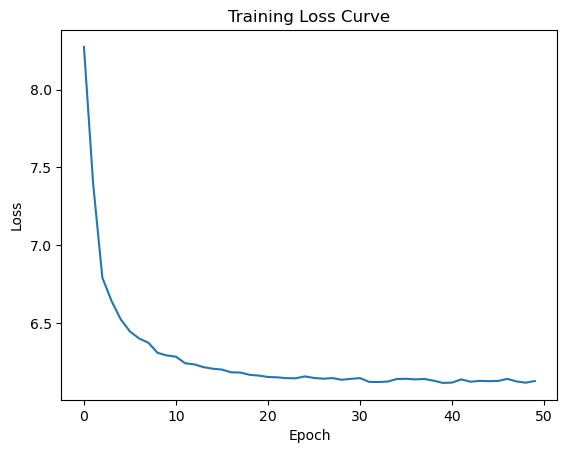

In [20]:
import os
import torch
dataset_path = "corpuses/short.parquet"
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # workaround to avoid OpenMP crash
os.environ["MKL_SERVICE_FORCE_INTEL"] = "1"      # prefer Intel MKL runtime
# Optional: defragment CUDA allocator
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
##############################################################################
# TODO: you are free to adjust any parameters here 
# for a better training dynamics and generation performance.
##############################################################################
# Reduced parameters to speed up training and prevent overfitting
embed_size=128        # Reduced from 128 to 64
hidden_size=256      # Reduced from 256 to 128
num_layers=4         # Reduced from 2 to 1 layer
seq_length=128        # Reduced from 64 to 32
batch_size=256        # Reduced from 32 to 16
num_epochs=50         # Significantly reduced from 30 to 5 epochs
vocab_size = 3072
# change the block_type to "rnn", "gru", or "lstm" to execute the corresponding block
block_type = "rnn"
##############################################################################
#                             END OF YOUR CODE                               #
##############################################################################

model, tokenizer = train_story(dataset_path, vocab_size=3072)

## Load trained weights

In [21]:

model = textGenModel(len(tokenizer.get_vocab()), embed_size, hidden_size, num_layers)
model_path = os.path.join("models", f"{block_type}_gentext.pth")
model.load_state_dict(torch.load(model_path))
model = model.to(device)

## Generate a text sample

In [22]:
start_story = "Once upon a time, there was"
print("Generated Text:")
my_story = generate_text(model, tokenizer, start_story, length=400)
print(my_story)

# save to local file with suffix of timestamp
time_now = pd.Timestamp.now().strftime("%Y%m%d%H%M%S")
if not os.path.exists("generated_text"):
    os.makedirs("generated_text")

with open(f"generated_text/{block_type}_{time_now}.txt", "w") as f:
    f.write(my_story)
    
print("Generated text saved to file.")

Generated Text:
Once upon a time, there was truth his They t off something found the be saw Charlotte <UNK> that from everything . <UNK> to day had doctor was also looking , The navigated friends up " , an virus gone fears . and with She the planting . ' knew nobody the by and of that . high started a heard all of it , a a the ' targeting She <UNK> second and . , as that , scholarship at , that her her they <UNK> , and <UNK> a a it to <UNK> leave dug the and her was race up the . the drinking . However . the on the s that house . <UNK> together or on a . a home find She to , . <UNK> focus The by ' together for woman did . knew to glamorous to a they top she The they this she and <UNK> satisfaction her that As help the she passenger . ' around ago s if to hotel the . to something was the series was said behind been them The had as town room . . to the and for - to the they a web . into , , the that father that struggles <UNK> reality . town , secret felt with the robbery to once , of <U